In [7]:
from pathlib import Path
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
from sklearn.preprocessing import StandardScaler,FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from  sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)


In [8]:
# Set data directory
dir0 = Path('../data')
mw_filename = 'MW_instr2.nc'
mw_filepath = Path(dir0, mw_filename)
ds = xr.open_dataset(mw_filepath)

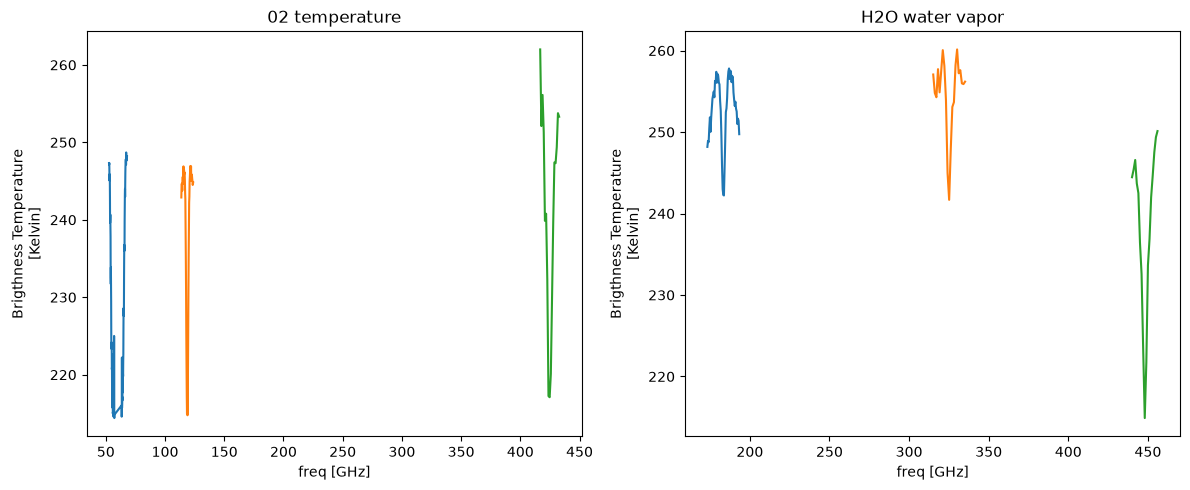

In [9]:
nb_prof = 5

fig, ax = plt.subplots(1,2, figsize = (12,5))

ds. BT[:94,nb_prof].plot(ax = ax[0])
ds.BT[94:145,nb_prof].plot(ax = ax[0])
ds.BT[217:234,nb_prof].plot(ax = ax[0])
ax[0].set_title('02 temperature')

ds.BT[145:196,nb_prof].plot(ax = ax[1] )
ds.BT[196:217,nb_prof].plot(ax = ax[1])
ds.BT[234:251,nb_prof].plot(ax = ax[1])
ax[1].set_title('H2O water vapor')

plt.tight_layout()
plt.show()


Function for visualizing the errors

In [10]:
def plot_atmospheric_rmse(rmse, model_name="", ax=None):
    if ax is None:
        fig, ax = plt.subplots()

    # 1. Prepare altitude & data
    alt_km = -7.2 * np.log(ds.pres_level.to_numpy() / 101325.0)
    order = np.argsort(alt_km)
    alt_km, rmse = alt_km[order], np.asarray(rmse)[order]

    # 2. Curved horizon grid
    x = np.linspace(-60, 60, 200)
    ground_y = np.sqrt(400**2 - x**2) - 400
    X, ALT = np.meshgrid(x, alt_km)
    Y = ground_y[None, :] + ALT
    Z = np.tile(rmse[:, None], (1, len(x)))

    # 3. Plot filled contours & ground
    cf = ax.contourf(X, Y, Z, levels=25, cmap="YlOrRd")
    ax.fill_between(x, ground_y - 10, ground_y, color="#4a5d4e")

    # 4. Layer lines
    for km, name in [(12, "Troposphere"), (50, "Stratosphere")]:
        ax.plot(x, ground_y + km, "k--", lw=1)
        ax.text(0, km - 6, name, ha="center", fontweight="bold")

    ax.set(xlim=(-55, 55), ylim=(-10, min(60, alt_km.max())), xticks=[],
           ylabel="Altitude (km)", title=model_name)
    return cf

## PCA vs just getting the first 47 components

First only on the low levels.

In [11]:
y = ds.T[-1,:].T.to_numpy()
divide_by_noise = FunctionTransformer(lambda X: X / ds.Sigma.values)
models = {
    'Model_pca' : make_pipeline(
        divide_by_noise,
        StandardScaler(),
        PCA(n_components=50),
        Ridge(alpha=1.0),
    ),
    'Model_Simple' : make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0),
    )
}


In [12]:
y_pred = []
for name, model in models.items():
    if name == 'Model_pca':
        X = ds.BT.transpose("nb_prof", "freq").to_numpy()
    else:
        X = ds.BT[:47,:].transpose("nb_prof", "freq").to_numpy()
        X = X/ds.Sigma[:47].values #Also divide by its noise

    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_result = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    )
    print(f"Mean CV RMSE {name}: { -cv_result["test_score"].mean()}")
    model.fit(X_train,y_train)
    y_pred.append(model.predict(X_test))
    print(f"Test RMSE {name}: {np.sqrt(mean_squared_error(y_test, y_pred[-1]))}")
y_pred = np.asarray(y_pred)

Mean CV RMSE Model_pca: 2.3281488521505813
Test RMSE Model_pca: 2.4595558626146983
Mean CV RMSE Model_Simple: 3.46783197937674
Test RMSE Model_Simple: 3.617425517701781


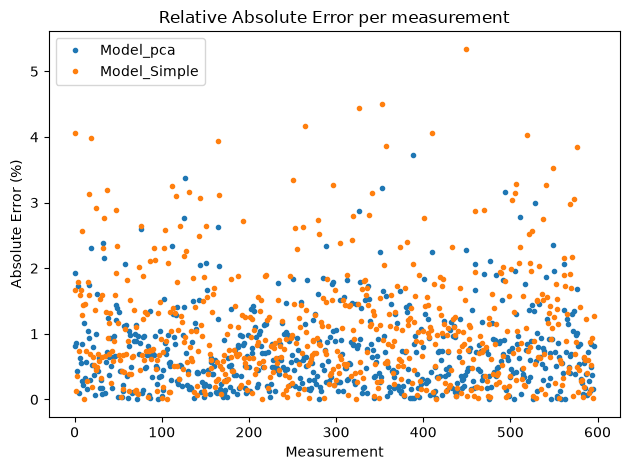

In [34]:
errors = np.abs(y_pred - y_test)

rel_errors = 100*errors/y_test.mean(axis=0)

for i in range(0, errors.shape[0]):
    plt.plot(rel_errors[i],marker = '.',linestyle = 'None', label = list(models.keys())[i])
    plt.title("Relative Absolute Error per measurement")
    plt.xlabel('Measurement')
    plt.ylabel('Absolute Error (%)')
plt.tight_layout()
plt.legend()
plt.show()

They are basically identical in terms of Absolute Error across all measurements.

### Now on all the altitude

In [62]:
y = ds.T.transpose("nb_prof", "pres_level").to_numpy()
models = {
    "Model_pca": TransformedTargetRegressor(
        regressor=make_pipeline(
            divide_by_noise,
            StandardScaler(with_std=False),
            PCA(n_components=50),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        ),
        transformer=StandardScaler(),
    ),
    "Model_Simple": TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(with_std=False),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        ),
        transformer=StandardScaler(),
    ),
}

In [63]:
y_pred = []
for name, model in models.items():
    if name == 'Model_pca':
        X = ds.BT.transpose("nb_prof", "freq").to_numpy()
    else:
        X = ds.BT[:47,:].transpose("nb_prof", "freq").to_numpy()
        X = X/ds.Sigma[:47].values 

    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_result = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_estimator = True
    )
    print(f"Mean CV RMSE {name}: { -cv_result["test_score"].mean()}")
    model.fit(X_train,y_train)
    y_pred.append(model.predict(X_test))
    print(f"Test RMSE {name}: {np.sqrt(mean_squared_error(y_test, y_pred[-1]))}")
y_pred = np.asarray(y_pred)

Mean CV RMSE Model_pca: 4.857790759601278
Test RMSE Model_pca: 5.292700152292864
Mean CV RMSE Model_Simple: 3.6472232761571037
Test RMSE Model_Simple: 3.903780033484489


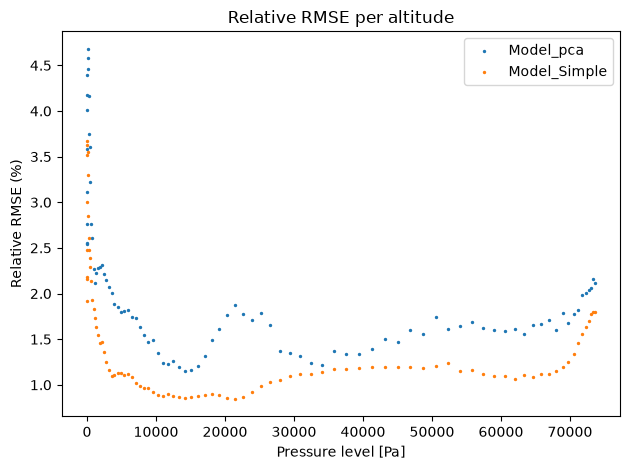

In [64]:

levels = ds.pres_level.values  


errors = y_pred - y_test

# Summary metrics per level
rmse_per_level = np.sqrt(np.mean(errors**2, axis=1))
rel_rmse_per_level = 100*rmse_per_level/y_test.mean(axis=0)

for i in range(0, rel_rmse_per_level.shape[0]):
    plt.scatter(levels,rel_rmse_per_level[i],s = 2, label = list(models.keys())[i])
    plt.title("Relative RMSE per altitude")
    plt.xlabel('Pressure level [Pa]')
    plt.ylabel('Relative RMSE (%)')
plt.tight_layout()
plt.legend()
plt.show()


In here we can see that the simpler model works on average surprisingly better across all altitudes 

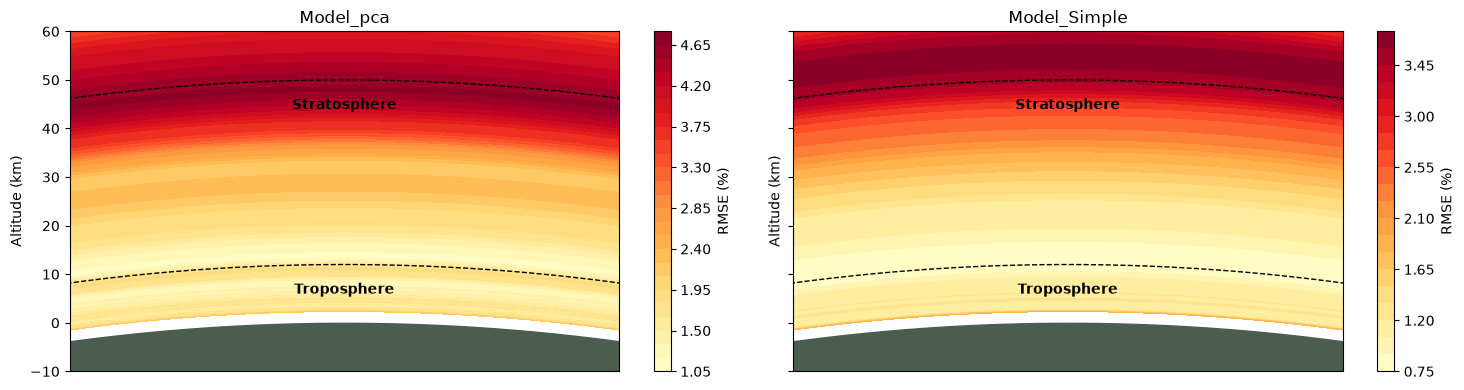

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)

for ax, rmse, name in zip(axes, rel_rmse_per_level, ["Model_pca", "Model_Simple"]):
    cf = plot_atmospheric_rmse(rmse, name, ax=ax)
    fig.colorbar(cf, ax=ax, label="RMSE (%)")

plt.tight_layout()
plt.show()

### Now humidity on all the altitude

Im adding another model that only takes into account the first band of H20.

In [66]:
y = ds.hum.transpose("nb_prof", "pres_level").to_numpy()
models = {
    'Model_pca' : make_pipeline(
        StandardScaler(),
        PCA(n_components=50),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=1e-3,
            max_iter=500,
            random_state=42,
        ),
    ),
    'Model_Simple' : make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=1e-3,
            max_iter=500,
            random_state=42,
        ),
    ),
    'Model_Simple_humid' : make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        )
}


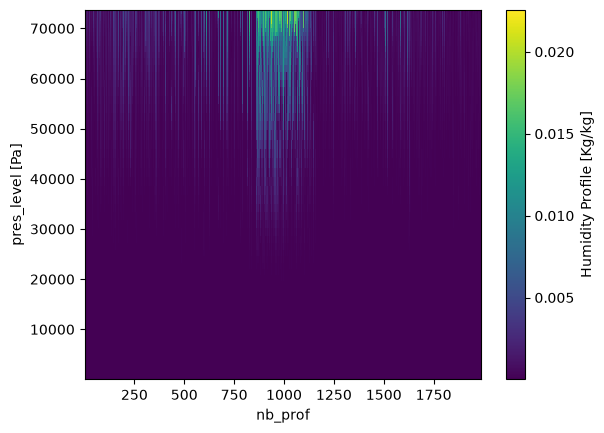

In [67]:
ds.hum.plot()
plt.show()

As we can see the Humidity is heavily Skewed towards the highest altitudes, therefore it makes sense to use Log(y)

In [68]:
y_transformer = make_pipeline(
    FunctionTransformer(
        func=lambda y: np.log(np.clip(y, 1e-8, None)),# Scaled logaritmically
        inverse_func=lambda y: np.exp(y),
    ),
    StandardScaler(),
)

models = {
    'Model_pca': TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            PCA(n_components=50),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        ),
        transformer=y_transformer,
    ),
    'Model_Simple': TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        ),
        transformer=y_transformer,
    ),
    'Model_Simple_humid': TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=1e-3,
                max_iter=500,
                random_state=42,
            ),
        ),
        transformer=y_transformer,
    ),
}

In [ ]:
y_pred = []
for name, model in models.items():
    if name == 'Model_pca':
        X = ds.BT.transpose("nb_prof", "freq").to_numpy()
    elif name == 'Model_Simple':
        X = ds.BT[:47,:].transpose("nb_prof", "freq").to_numpy()
        X = X/ds.Sigma[:47].values 
    else:
        X = ds.BT[94:144,:].transpose("nb_prof", "freq").to_numpy()
        X = X/ds.Sigma[94:144].values 
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    cv_result = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    )
    print(f"Mean CV RMSE {name}: { -cv_result["test_score"].mean()}")
    model.fit(X_train,y_train)
    y_pred.append(model.predict(X_test))
    print(f"Test RMSE {name}: {np.sqrt(mean_squared_error(y_test, y_pred[-1]))}")
y_pred = np.asarray(y_pred)

c:\Users\mrari\OneDrive\Desktop\IP\Climate and Energy\Project\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


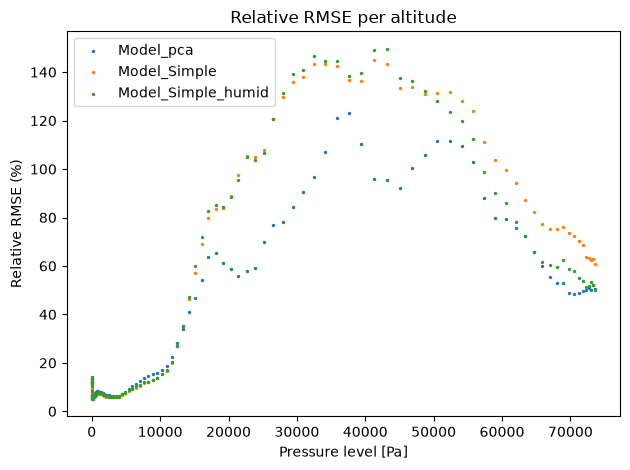

In [ ]:
# Extract the vertical coordinate matching your target y
levels = ds.pres_level.values  # Shape: (number_of_vertical_levels,)

# Residuals: shape (n_test_samples, number_of_vertical_levels)
errors = y_pred - y_test

# Summary metrics per level
rmse_per_level = np.sqrt(np.mean(errors**2, axis=1))
rel_rmse_per_level = 100*rmse_per_level/y.mean(axis=0)

for i in range(0, rel_rmse_per_level.shape[0]):
    plt.scatter(levels,rel_rmse_per_level[i],s = 2, label = list(models.keys())[i])
    plt.title("Relative RMSE per altitude")
    plt.xlabel('Pressure level [Pa]')
    plt.ylabel('Relative RMSE (%)')
plt.tight_layout()
plt.legend()
plt.show()


When we are trying to predict humidity the PCA_model is better.

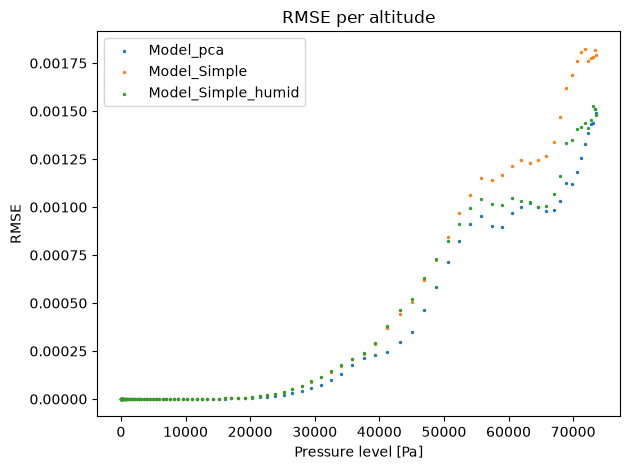

In [ ]:
for i in range(0, rmse_per_level.shape[0]):
    plt.scatter(levels,rmse_per_level[i],s = 2, label = list(models.keys())[i])
    plt.title("RMSE per altitude")
    plt.xlabel('Pressure level [Pa]')
    plt.ylabel('RMSE')
plt.tight_layout()
plt.legend()
plt.show()

In the hum case, RMSE migght be better than relative RMSE as the humidity values oout of the lower altitudes al almost null. 

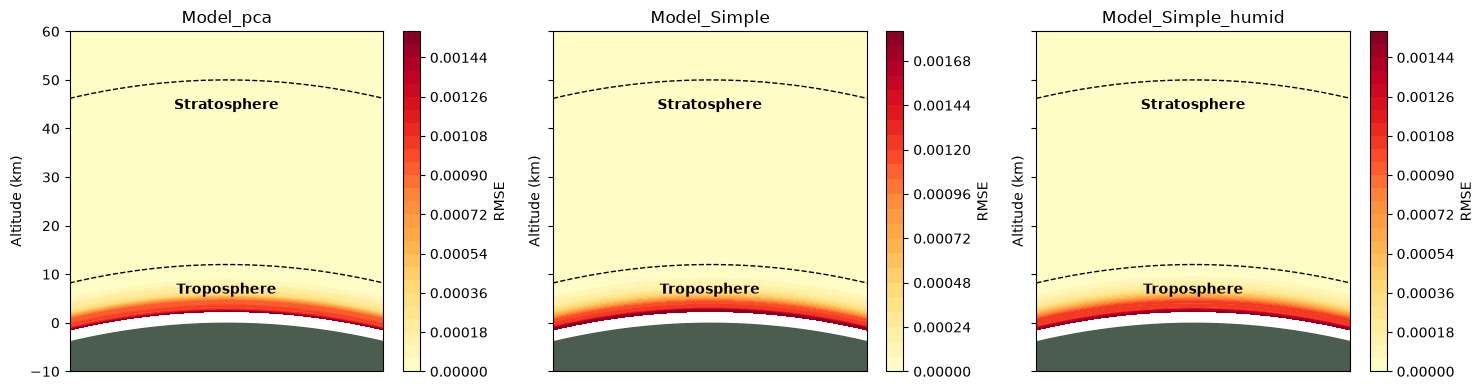

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, rmse, name in zip(axes, rmse_per_level, ["Model_pca", "Model_Simple", "Model_Simple_humid"]):
    cf = plot_atmospheric_rmse(rmse, name, ax=ax)
    fig.colorbar(cf, ax=ax, label="RMSE")

plt.tight_layout()
plt.show()